# 🐦 Bird Species Classification — Stage-by-Stage Preprocessing Pipeline
.

### 📁 Dataset Directory Architecture
```
Dataset/
├── Raw/                 <- Original bird images organized by species folders
├── Birds_crop/          <- Step 1: Bird localized and cropped using YOLOv8
├── Birds_segmented/     <- Step 2: Background removed using Otsu's thresholding
└── Birds_preprocessed/  <- Step 3: Final normalized grayscale images (128x128)
```

---
## ⚙️ Setup & Dependencies

In [16]:
!pip install ultralytics opencv-python matplotlib

import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Set base paths
RAW_DIR = "../Dataset/Raw"
CROP_DIR = "../Dataset/Birds_crop"
SEGMENTED_DIR = "../Dataset/Birds_segmented"
PREPROCESSED_DIR = "../Dataset/Birds_preprocessed"

# Load lightweight YOLOv8n detector
yolo_model = YOLO("yolov8n.pt")

---
## Collect Sample Images
A helper function to pick random sample image paths from the dataset for visual inspection.

In [17]:
def get_sample_images(base_dir, n=5):
    all_images = []
    for root, _, files in os.walk(base_dir):
        for f in files:
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                all_images.append(os.path.join(root, f))
    return random.sample(all_images, min(n, len(all_images)))

---
## Stage 1: Bird Detection & Bounding Box Cropping (YOLOv8)
Detects the bird in the frame and crops away surrounding background/distractions.

In [18]:
def detect_and_crop(img_bgr):
    """
    Detects the main bird object using YOLO and returns the cropped bounding box region.
    """
    results = yolo_model(img_bgr, verbose=False)
    for result in results:
        boxes = result.boxes
        if len(boxes) > 0:
            best_box_idx = boxes.conf.argmax().item()
            xyxy = boxes.xyxy[best_box_idx].cpu().numpy().astype(int)
            x1, y1, x2, y2 = xyxy
            cropped = img_bgr[y1:y2, x1:x2]
            if cropped.size > 0:
                return cropped
    return img_bgr  # Fallback if no bird detected

### 5 Random Samples (Raw vs. Cropped)

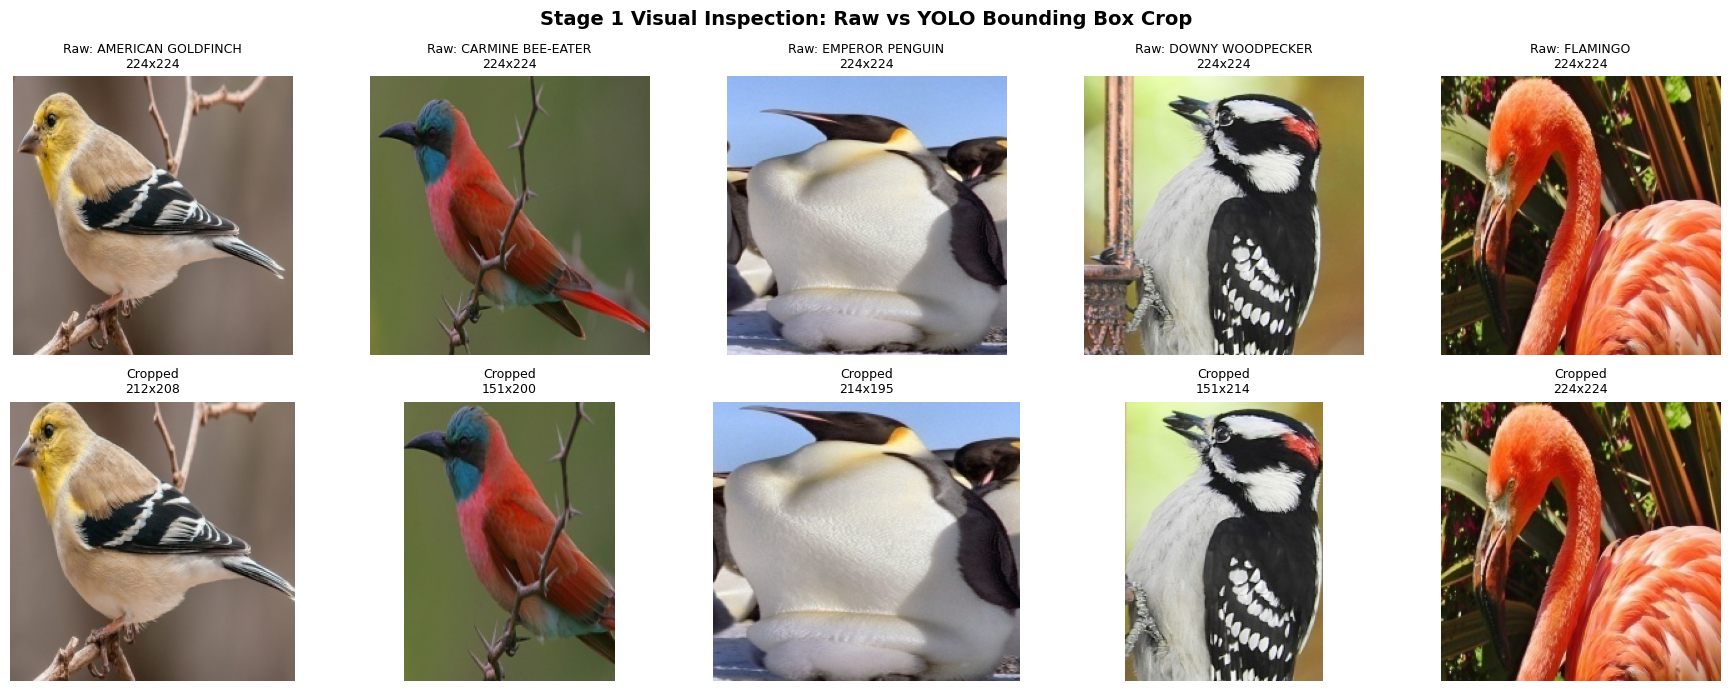

In [19]:
sample_paths = get_sample_images(RAW_DIR, n=5)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for i, img_path in enumerate(sample_paths):
    orig_bgr = cv2.imread(img_path)
    crop_bgr = detect_and_crop(orig_bgr)
    
    orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
    crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    
    species = os.path.basename(os.path.dirname(img_path))
    axes[0, i].imshow(orig_rgb)
    axes[0, i].set_title(f"Raw: {species}\n{orig_bgr.shape[1]}x{orig_bgr.shape[0]}", fontsize=9)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(crop_rgb)
    axes[1, i].set_title(f"Cropped\n{crop_bgr.shape[1]}x{crop_bgr.shape[0]}", fontsize=9)
    axes[1, i].axis('off')

plt.suptitle("Stage 1 Visual Inspection: Raw vs YOLO Bounding Box Crop", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### Batch Process: Apply YOLO Cropping to All Images 

In [20]:
count = 0
for species_name in os.listdir(RAW_DIR):
    species_raw_path = os.path.join(RAW_DIR, species_name)
    if not os.path.isdir(species_raw_path):
        continue
        
    species_dest_path = os.path.join(CROP_DIR, species_name)
    os.makedirs(species_dest_path, exist_ok=True)
    
    for img_name in os.listdir(species_raw_path):
        if img_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            src_img_path = os.path.join(species_raw_path, img_name)
            dest_img_path = os.path.join(species_dest_path, img_name)
            
            img = cv2.imread(src_img_path)
            if img is not None:
                cropped = detect_and_crop(img)
                cv2.imwrite(dest_img_path, cropped)
                count += 1

print(f"✅ Successfully processed and saved {count} cropped images to: {CROP_DIR}")

✅ Successfully processed and saved 811 cropped images to: ../Dataset/Birds_crop


---
## Stage 2: Background Segmentation (Otsu's Thresholding)
Converts cropped images to grayscale, reduces high-frequency noise with Gaussian Blur, and isolates the bird using Otsu's thresholding.

In [21]:
def segment_foreground(img_bgr_or_gray):
    """
    Applies Gaussian Blur and Otsu's Thresholding to isolate foreground pixels.
    """
    if len(img_bgr_or_gray.shape) == 3:
        gray = cv2.cvtColor(img_bgr_or_gray, cv2.COLOR_BGR2GRAY)
    else:
        gray = img_bgr_or_gray
        
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    _, binary_mask = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    segmented = cv2.bitwise_and(gray, gray, mask=binary_mask)
    return segmented

###  Visual Demo: 5 Random Samples (Cropped vs. Segmented)

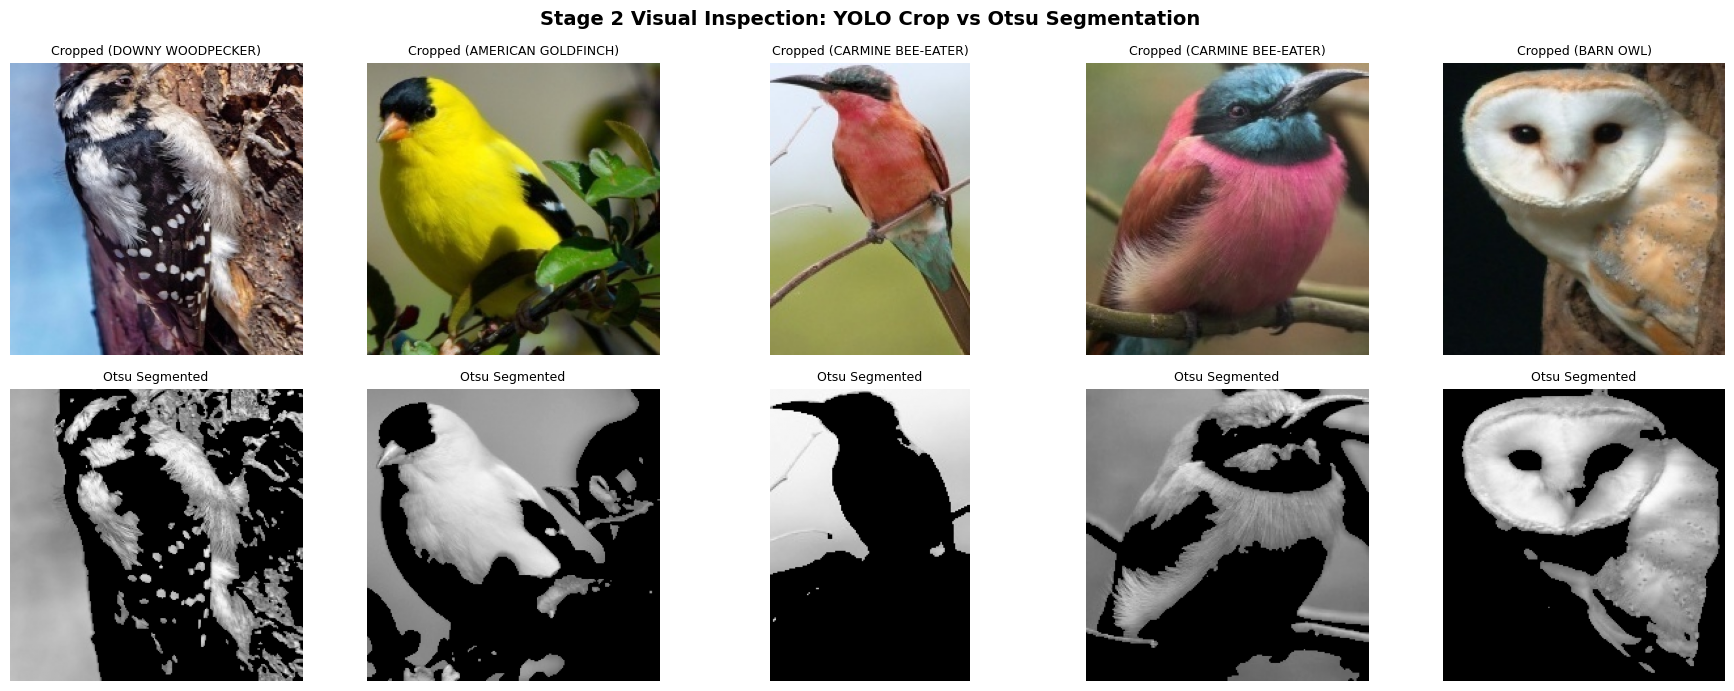

In [22]:
sample_paths = get_sample_images(CROP_DIR, n=5)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for i, img_path in enumerate(sample_paths):
    crop_bgr = cv2.imread(img_path)
    seg_gray = segment_foreground(crop_bgr)
    crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    
    species = os.path.basename(os.path.dirname(img_path))
    axes[0, i].imshow(crop_rgb)
    axes[0, i].set_title(f"Cropped ({species})", fontsize=9)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(seg_gray, cmap='gray')
    axes[1, i].set_title("Otsu Segmented", fontsize=9)
    axes[1, i].axis('off')

plt.suptitle("Stage 2 Visual Inspection: YOLO Crop vs Otsu Segmentation", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### 💾 Batch Process: Apply Otsu Segmentation to All Images & Save to `Dataset/Birds_segmented/`

In [23]:
count = 0
for species_name in os.listdir(CROP_DIR):
    species_crop_path = os.path.join(CROP_DIR, species_name)
    if not os.path.isdir(species_crop_path):
        continue
        
    species_dest_path = os.path.join(SEGMENTED_DIR, species_name)
    os.makedirs(species_dest_path, exist_ok=True)
    
    for img_name in os.listdir(species_crop_path):
        if img_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            src_img_path = os.path.join(species_crop_path, img_name)
            dest_img_path = os.path.join(species_dest_path, img_name)
            
            img = cv2.imread(src_img_path)
            if img is not None:
                segmented = segment_foreground(img)
                cv2.imwrite(dest_img_path, segmented)
                count += 1

print(f"✅ Successfully processed and saved {count} segmented images to: {SEGMENTED_DIR}")

✅ Successfully processed and saved 811 segmented images to: ../Dataset/Birds_segmented


---
##  Stage 3: Spatial Normalization & Resizing (128x128)
Normalizes all images to a standardized resolution of 128x128 pixels, ready for feature extraction (HOG & LBP).

In [24]:
def resize_image(img, target_size=(128, 128)):
    return cv2.resize(img, target_size)

### Visual Demo: 5 Random Samples (Final Normalized 128x128)

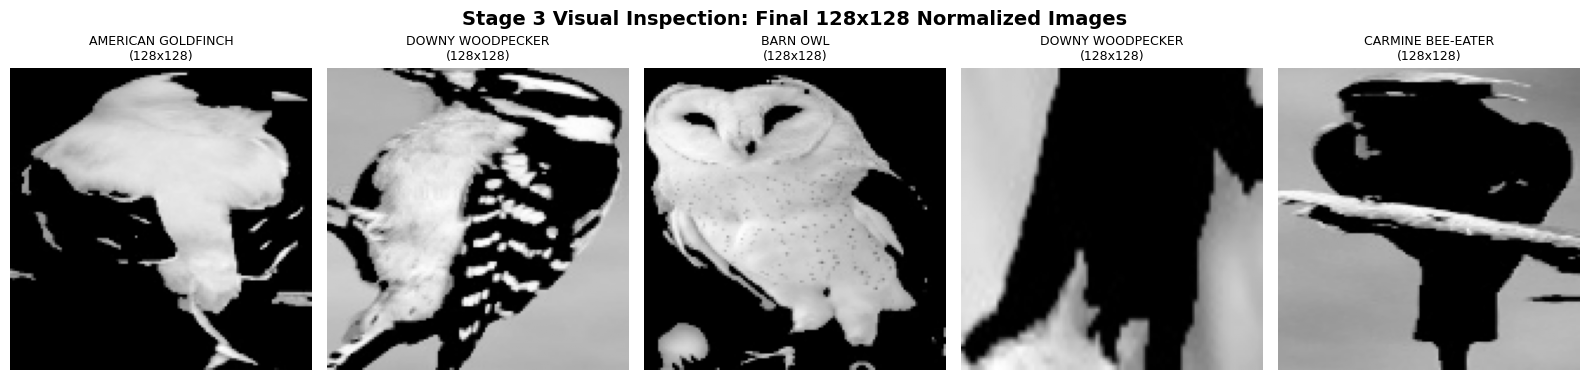

In [25]:
sample_paths = get_sample_images(SEGMENTED_DIR, n=5)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, img_path in enumerate(sample_paths):
    seg_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    final_img = resize_image(seg_img, target_size=(128, 128))
    
    species = os.path.basename(os.path.dirname(img_path))
    axes[i].imshow(final_img, cmap='gray')
    axes[i].set_title(f"{species}\n(128x128)", fontsize=9)
    axes[i].axis('off')

plt.suptitle("Stage 3 Visual Inspection: Final 128x128 Normalized Images", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### 💾 Batch Process: Resize All Images & Save to `Dataset/Birds_preprocessed/`

In [26]:
count = 0
for species_name in os.listdir(SEGMENTED_DIR):
    species_seg_path = os.path.join(SEGMENTED_DIR, species_name)
    if not os.path.isdir(species_seg_path):
        continue
        
    species_dest_path = os.path.join(PREPROCESSED_DIR, species_name)
    os.makedirs(species_dest_path, exist_ok=True)
    
    for img_name in os.listdir(species_seg_path):
        if img_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            src_img_path = os.path.join(species_seg_path, img_name)
            dest_img_path = os.path.join(species_dest_path, img_name)
            
            img = cv2.imread(src_img_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                resized = resize_image(img, target_size=(128, 128))
                cv2.imwrite(dest_img_path, resized)
                count += 1

print(f"✅ Successfully processed and saved {count} final preprocessed images to: {PREPROCESSED_DIR}")
print("🎉 Preprocessing Pipeline Complete!")

✅ Successfully processed and saved 811 final preprocessed images to: ../Dataset/Birds_preprocessed
🎉 Preprocessing Pipeline Complete!
